<a href="https://colab.research.google.com/github/isakinolajuwon-dotcom/nextflow-cloud-dev/blob/main/PMx.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
X <- 2
X

[1] 2

In [5]:
conc <- read.csv("/content/conc.csv")
conc_raw <- conc
conc

SubjIdent,Time,Conc,Analyte
<int>,<dbl>,<chr>,<chr>
1,24.0,8091.5,biomarker
1,0.5,1245.9,met1
1,1.0,5790.7,met1
1,2.0,8173.4,met1
1,4.0,10294,met1
1,6.0,9307.2,met1
1,8.0,10048,met1
1,0.5,9836.2,parent
1,1.0,9555.5,parent


`geom_line()`: Each group consists of only one observation.
ℹ Do you need to adjust the group aesthetic?


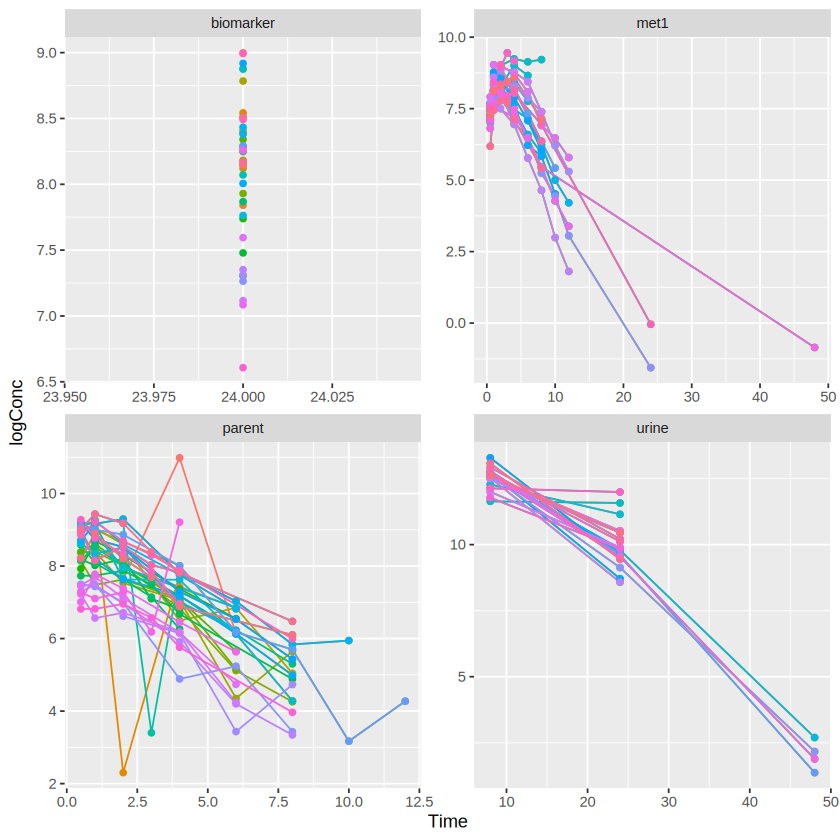

In [ ]:
library(ggplot2)

conc <- conc[!grepl("<", conc$Conc), ]
conc$Conc <- as.numeric(as.character(conc$Conc))
conc <- conc[!is.na(conc$Conc) & conc$Conc > 0, ]
conc$logConc <- log(conc$Conc)

ggplot(conc, aes(x = Time, y = logConc,
                 color = factor(SubjIdent),
                                  group = SubjIdent)) +
                                    geom_line() +
                                      geom_point() +
                                        facet_wrap(~ Analyte, scales = "free") +
                                          theme(legend.position = "none")

In [ ]:
sum(conc$Conc < 0, na.rm = TRUE)

[1] 6

In [ ]:
library(dplyr)

bounce <- conc %>%
  filter(Analyte == "parent") %>%
    arrange(SubjIdent, Time) %>%
      group_by(SubjIdent) %>%
        mutate(prev = lag(Conc), ratio = Conc / prev) %>%
          ungroup() %>%
            filter(Time > 2, ratio > 2)

            bounce


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


Warning message:
“There were 42 warnings in `mutate()`.
The first warning was:
ℹ In argument: `ratio = Conc/prev`.
ℹ In group 1: `SubjIdent = 1`.
Caused by warning in `Ops.factor()`:
! ‘/’ not meaningful for factors
ℹ Run `dplyr::last_dplyr_warnings()` to see the 41 remaining warnings.”


SubjIdent,Time,Conc,Analyte,prev,ratio
<int>,<dbl>,<fct>,<fct>,<fct>,<lgl>


Warning message:
“NAs introduced by coercion”


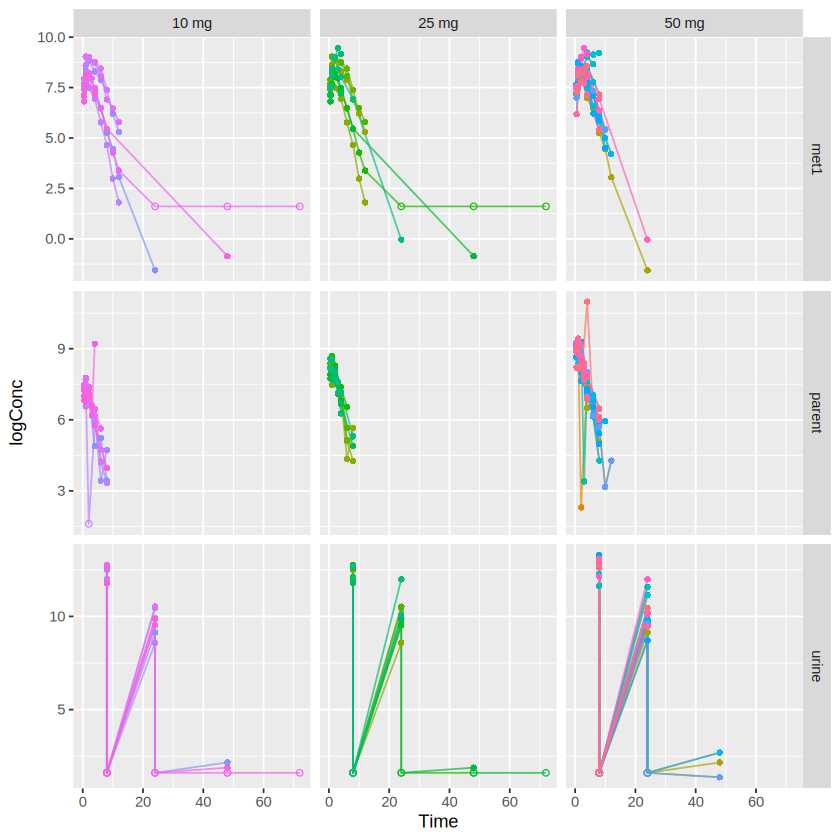

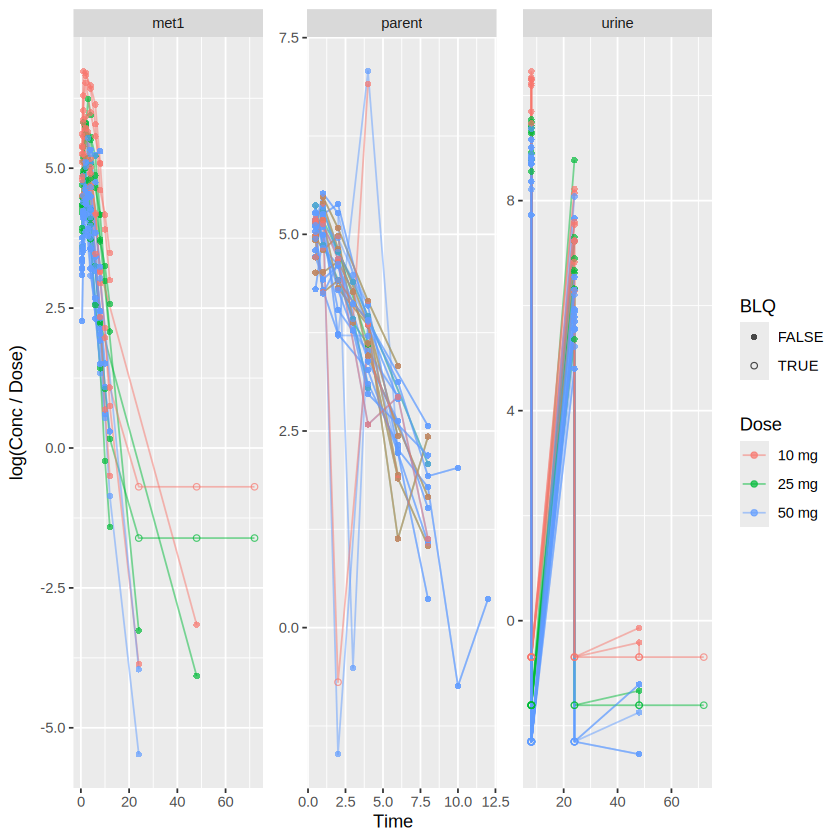

In [6]:
library(ggplot2)

# ---- Prep ----
conc <- conc_raw
conc$BLQ <- grepl("<", conc$Conc)
conc$Conc_num <- as.numeric(gsub("<", "", as.character(conc$Conc)))
conc$Conc_num[conc$BLQ] <- 5                          # half the LLOQ (10)
conc <- conc[!(conc$BLQ & conc$Time == 0), ]          # drop pre-dose BLQ
conc <- conc[!is.na(conc$Conc_num) & conc$Conc_num > 0, ]
conc$logConc <- log(conc$Conc_num)

# ---- Dose ----
dose <- read.csv("/content/dose.csv")
dose$AMT <- as.numeric(gsub("[^0-9.]", "", dose$AMT))
conc <- merge(conc, dose, by.x = "SubjIdent", by.y = "CID")
conc$Dose <- factor(paste(conc$AMT, "mg"),
                    levels = c("10 mg", "25 mg", "50 mg"))
                    conc$logDN <- conc$logConc - log(conc$AMT)

                    tc <- subset(conc, Analyte != "biomarker")

                    # ---- Plot 1: faceted by dose ----
                    ggplot(tc, aes(Time, logConc, group = SubjIdent,
                                   color = factor(SubjIdent))) +
                                     geom_line(alpha = 0.7) +
                                       geom_point(aes(shape = BLQ)) +
                                         scale_shape_manual(values = c(16, 1)) +
                                           facet_grid(Analyte ~ Dose, scales = "free_y") +
                                             theme(legend.position = "none")

                                             # ---- Plot 2: dose-normalized, colored by dose ----
                                             ggplot(tc, aes(Time, logDN, group = SubjIdent, color = Dose)) +
                                               geom_line(alpha = 0.5) +
                                                 geom_point(aes(shape = BLQ), alpha = 0.7) +
                                                   scale_shape_manual(values = c(16, 1)) +
                                                     facet_wrap(~ Analyte, scales = "free") +
                                                       labs(y = "log(Conc / Dose)")